In [2]:
!pip install yfinance pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 1.7 MB/s  0:00:01 eta 0:00:01
  Attempting uninstall: cffi
    Found existing installation: cffi 2.1.0
    Uninstalling cffi-2.1.0:
      Successfully uninstalled cffi-2.1.0━━━━━━━━━━━━━━━━━━━━━━━━━ 1/5 [cffi]
  Attempting uninstall: certifi━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/5 [cffi]
    Found existing installation: certifi 2026.6.17━━━━━━━━━━━━ 1/5 [cffi]
    Uninstalling certifi-2026.6.17:━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/5 [cffi]
      Successfully uninstalled certifi-2026.6.17━━━━━━━━━━━━━━ 1/5 [cffi]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [yfinance]3/5 [curl_cffi]


In [3]:
import yfinance as yf
import pandas as pd

# ==========================================
# STEP 1: DATA INGESTION
# ==========================================
# We define our list of bank tickers. 
# Note: We are using the US stock tickers for the UK banks (HSBC and BCS) 
# so that the trading days align perfectly with the US banks (JPM and C).
bank_tickers = ['HSBC', 'BCS', 'JPM', 'C']

# Download 5 years of daily market data for all four banks at once.
# We specify ['Close'] because we only care about the daily closing prices,
# not the open, high, low, or trading volume.
print("Downloading bank data...")
raw_data = yf.download(bank_tickers, period="5y")['Close']


# ==========================================
# STEP 2: DATA CLEANING
# ==========================================
# When pulling data across multiple years, some days might have missing values 
# (NaN) due to unexpected market closures or data glitches. 
# .ffill() takes the previous day's price and carries it forward to fill the gap.
# .dropna() removes any remaining rows that couldn't be fixed.
clean_data = raw_data.ffill().dropna()

# Rename the columns to make them look professional in our final charts
clean_data.columns = ['Barclays', 'Citigroup', 'HSBC', 'JPMorgan']

# Display the first 5 rows to confirm it worked
print("\nData cleaned successfully! Here are the first 5 rows:")
clean_data.head()

[*********************100%***********************]  4 of 4 completed



Data cleaned successfully! Here are the first 5 rows:


,Barclays,Citigroup,HSBC,JPMorgan
Date,,,,
2021-11-10,8.790083,57.606701,21.264149,148.061584
2021-11-11,8.940913,58.164089,21.330376,148.052750
2021-11-12,8.899014,58.409012,21.337734,147.390228
2021-11-15,8.949293,58.054302,21.543749,147.125259
2021-11-16,8.924152,57.209740,21.698265,146.065262


In [4]:
import numpy as np

# ==========================================
# STEP 3: FINANCIAL MATH
# ==========================================

# 1. Calculate Daily Percentage Returns
# .pct_change() calculates the percentage difference between today's price and yesterday's price.
daily_returns = clean_data.pct_change().dropna()

# 2. Calculate Annualized Volatility (Risk)
# We take the standard deviation of the daily returns and multiply it by the square root of 252 
# (the standard number of trading days in a year).
annual_volatility = daily_returns.std() * np.sqrt(252)

# 3. Calculate Cumulative Return
# We divide the very last price in our dataset by the very first price, and subtract 1.
# (e.g., if a stock went from $100 to $150, (150/100) - 1 = 0.50, or a 50% return).
cumulative_return = (clean_data.iloc[-1] / clean_data.iloc[0]) - 1

# 4. Combine into a Summary Table
summary_stats = pd.DataFrame({
    'Cumulative Return': cumulative_return,
    'Annualized Volatility (Risk)': annual_volatility
})

# Format the results as percentages for a clean presentation
summary_stats = summary_stats.applymap(lambda x: f"{x:.2%}")

print("\n--- 5-Year Risk vs. Return Summary ---")
summary_stats

AttributeError: 'DataFrame' object has no attribute 'applymap'

In [5]:
import numpy as np

# ==========================================
# STEP 3: FINANCIAL MATH
# ==========================================

# 1. Calculate Daily Percentage Returns
daily_returns = clean_data.pct_change().dropna()

# 2. Calculate Annualized Volatility (Risk)
annual_volatility = daily_returns.std() * np.sqrt(252)

# 3. Calculate Cumulative Return
cumulative_return = (clean_data.iloc[-1] / clean_data.iloc[0]) - 1

# 4. Combine into a Summary Table
summary_stats = pd.DataFrame({
    'Cumulative Return': cumulative_return,
    'Annualized Volatility (Risk)': annual_volatility
})

# Format the results as percentages for a clean presentation
# FIX: Changed .applymap() to .map() for newer Pandas versions
summary_stats = summary_stats.map(lambda x: f"{x:.2%}")

print("\n--- 5-Year Risk vs. Return Summary ---")
summary_stats


--- 5-Year Risk vs. Return Summary ---


,Cumulative Return,Annualized Volatility (Risk)
Barclays,162.80%,34.28%
Citigroup,112.02%,29.45%
HSBC,323.39%,26.19%
JPMorgan,131.31%,24.45%


In [6]:
!pip install matplotlib

Matplotlib is building the font cache; this may take a moment.


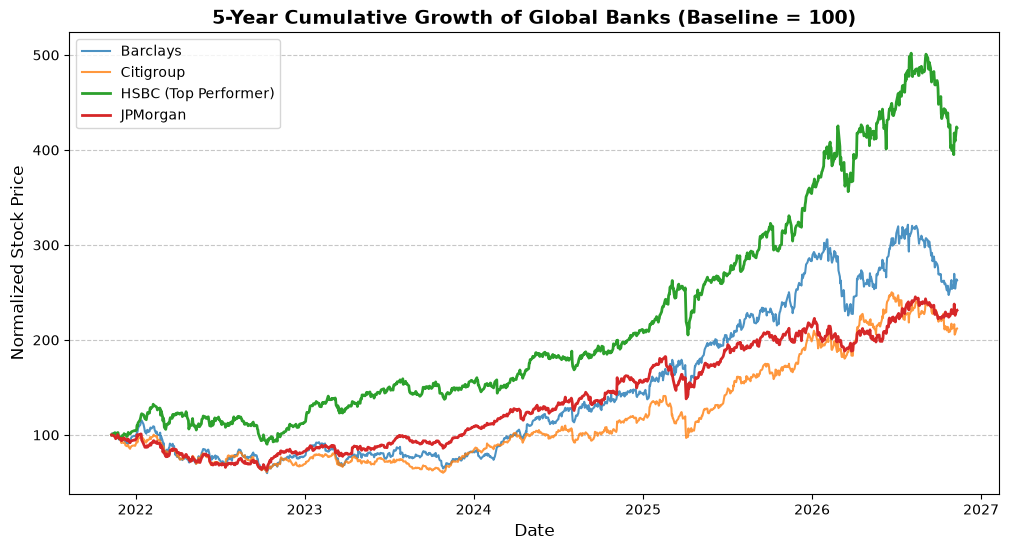

In [7]:
import matplotlib.pyplot as plt

# ==========================================
# STEP 4: VISUALIZATION (Time Series)
# ==========================================

# Normalize the prices to 100 at the start of the 5-year period.
# This mathematically aligns all four banks at the same starting line 
# so we can perfectly compare their growth trajectories.
normalized_prices = (clean_data / clean_data.iloc[0]) * 100

# Set up the canvas
plt.figure(figsize=(12, 6))

# Plot each bank's performance
plt.plot(normalized_prices.index, normalized_prices['Barclays'], label='Barclays', alpha=0.8)
plt.plot(normalized_prices.index, normalized_prices['Citigroup'], label='Citigroup', alpha=0.8)
plt.plot(normalized_prices.index, normalized_prices['HSBC'], label='HSBC (Top Performer)', linewidth=2)
plt.plot(normalized_prices.index, normalized_prices['JPMorgan'], label='JPMorgan', linewidth=2)

# Add professional formatting, titles, and labels
plt.title('5-Year Cumulative Growth of Global Banks (Baseline = 100)', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Normalized Stock Price', fontsize=12)
plt.legend(loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Display the final chart
plt.show()